<a href="https://colab.research.google.com/github/brooklynnsudler-collab/Brooklynn_INFO4670_Fall2026/blob/main/Sudler_Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [42]:
dataset = pd.read_csv('car_purchase_data.csv')

### Step 2: Split features and target

In [43]:
X = dataset.drop(['Purchased'], axis=1)
Y = dataset[['Purchased']]

### Step 3: Train/Test Split

In [44]:
#first 5 records
X.head()

,User ID,Gender,Age,Salary
0,15624510,Male,19,19000
1,15810944,Male,35,20000
2,15668575,Female,26,43000
3,15603246,Female,27,57000
4,15804002,Male,19,76000


In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

### Step 4: Feature Scaling

In [46]:
from sklearn.preprocessing import StandardScaler

# Slicing only 'Age' and 'Salary' as required by the assignment goal
X_train_features = X_train[['Age', 'Salary']]
X_test_features = X_test[['Age', 'Salary']]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_features)
X_test_scaled = scaler.transform(X_test_features)

### Step 5: Train Logistic Regression Model

In [47]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_scaled, Y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

### Step 6: Predict and Evaluate

In [48]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(Y_test, Y_pred)
print(f"Accuracy: {accuracy}")

print("Confusion Matrix:")
print(confusion_matrix(Y_test, Y_pred))

print("Classification Report:")
print(classification_report(Y_test, Y_pred))

Accuracy: 0.8375
Confusion Matrix:
[[48  3]
 [10 19]]
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.94      0.88        51
           1       0.86      0.66      0.75        29

    accuracy                           0.84        80
   macro avg       0.85      0.80      0.81        80
weighted avg       0.84      0.84      0.83        80



### Step 7: Visualization of Decision Regions

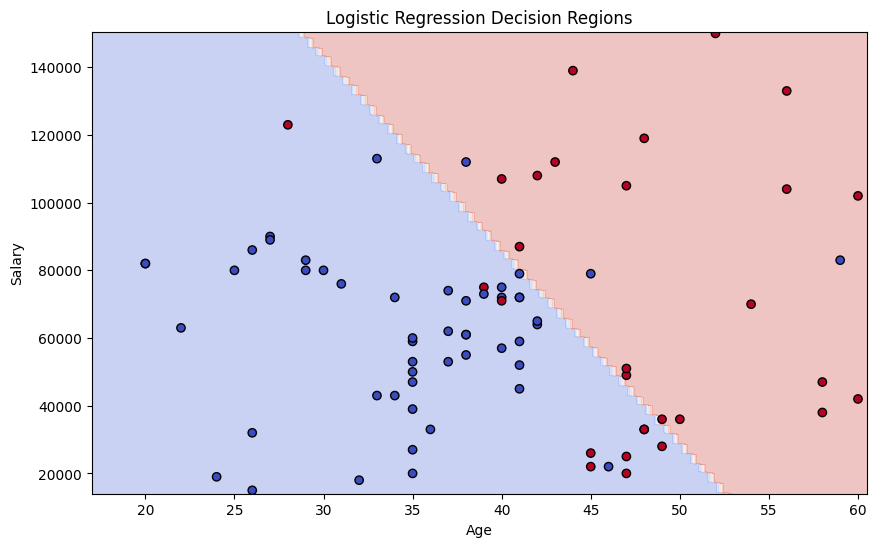

In [49]:
#grid covering Age and Salary ranges with appropriate step sizes
age_min, age_max = X_train['Age'].min() - 1, X_train['Age'].max() + 1
salary_min, salary_max = X_train['Salary'].min() - 1000, X_train['Salary'].max() + 1000

# Age steps by 0.5, Salary steps by 500
xx, yy = np.meshgrid(
    np.arange(age_min, age_max, 0.5),
    np.arange(salary_min, salary_max, 500)
)

#combining grid points and scaling
grid = pd.DataFrame({
    'Age': xx.ravel(),
    'Salary': yy.ravel()
    })
grid_scaled = scaler.transform(grid)

#predicting on grid points
Z = model.predict(grid_scaled)
Z = Z.reshape(xx.shape)

#plotting decision regions
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

#plot actual test customers
plt.scatter(
    X_test['Age'],
    X_test['Salary'],
    c=Y_test.values.ravel(),
    cmap='coolwarm',
    edgecolors='black'
)

plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('Logistic Regression Decision Regions')
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1. While logistic regression outputs probabilities, it can still be used for classification because it tranforms linear combinations of input features into probability scores between 0 and 1. This way, it can be mapped into descrete classes.

2. Based on my model, it could be assumed that customers over the age 40 with yearly salaries of over $100,000 may be more likely to purchase a car.

3. Low accuracy could be caused by factors such as limited features, overlapping customer patterns, and model limitations. The model only uses Age and Salary, however, other outside factors could influence a customer's decision to purchase a car. Also, customers with similar ages and salaries might make completely difference purchasing decisions. The use of a linear model could also lower the accuracy slightly because it might not capture the more complex relationships between customer characteristics and purchasing behavior. However, my model contained an accuracy of 83.75%, indicating that it could still be a relyable tool for predicting a majority of customer purchasing behavior.

4. Three additional features I think could be useful would be adding customers' credit score, employment status, and previous purchase history. Credit scores and employment status could evaluate a customer's financial circumstances and financing options, overall influeincing their decision of purchasing a car. And evaluating previous purchase history could reveal patterns in past purchasing behavior.